<a href="https://colab.research.google.com/github/amanvashisth/Deep-Learning/blob/master/PyTorch/autograd_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch


In [ ]:
if torch.cuda.is_available():
  print(f"GPU available: {torch.cuda.get_device_name()}")
else:
  print("No GPU is available")

GPU available: Tesla T4


# **What is Autograd in PyTorch?**
Autograd is PyTorch's automatic differentiation engine. It automatically calculates gradients (derivatives) of tensors with respect to other tensors, which is essential for training neural networks using backpropagation.

In simple terms, instead of calculating derivatives manually, you let PyTorch calculate them for you.

In [ ]:
# requires_grad = True helps to know pytorch that we want to calculate gradient of that particular tensor
x = torch.tensor(3.0, requires_grad=True)

In [ ]:
# Relationship between X and Y
y = x**2

In [ ]:
x

tensor(3., requires_grad=True)

In [ ]:
y

tensor(9., grad_fn=<PowBackward0>)

**grad_fn=**

Short for gradient function. It indicates that PyTorch is tracking how this tensor was calculated so it can compute gradients during backpropagation.

**PowBackward0**

This identifies the backward operation associated with exponentiation (**). PyTorch uses it to calculate gradients when propagating backward through the computational graph.

In [ ]:
# y.backward() is to calculate the gradient (derivative) of y with respect to the tensors that were used to calculate it and have gradient tracking enabled.
y.backward()

- Attribute: object.property
- Function call: object.function()

grad is a property of the tensor, not a function.

In [ ]:
x.grad

tensor(6.)

In [ ]:
# Example 2
# Where y = x**2 and z = sin(y)
import math

def dz_dx(x):
    return 2 * x * math.cos(x**2)

In [ ]:
dz_dx(4)

-7.661275842587077

In [ ]:
# Using Grad
x = torch.tensor(4.0, requires_grad=True)

In [ ]:
y = x**2

In [ ]:
z = torch.sin(y)

In [ ]:
x

tensor(4., requires_grad=True)

In [ ]:
y

tensor(16., grad_fn=<PowBackward0>)

In [ ]:
z

tensor(-0.2879, grad_fn=<SinBackward0>)

In [ ]:
z.backward()

In [ ]:
x.grad

tensor(-7.6613)

In [ ]:
# This will give an error because The .grad attribute of a Tensor that is not a leaf Tensor is being accessed.
# Its .grad attribute won't be populated during autograd.backward().
# If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor.
# If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead.
# bacially you can't access a non leaf node/intermediate node while calculating the gradient

y.grad

/tmp/ipykernel_1619/486760323.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  y.grad



### PyTorch Computation Graph

```text
x = torch.tensor(4.0, requires_grad=True)
            |
            v
        y = x ** 2
            |
            v
        z = sin(y)
```

**Step-by-step:**

- **Input:** `x = 4.0`, with `requires_grad=True`
- **First operation:** `y = x² = 16`
- **Second operation:** `z = sin(y) = sin(16) ≈ -0.2879`

**Autograd:**

- `y.grad_fn` → `PowBackward0`
- `z.grad_fn` → `SinBackward0`

**Backpropagation:**

When we call `z.backward()`, PyTorch calculates the gradient using the chain rule:

Therefore, `x.grad ≈ -0.5820`.

**Note:** `torch.sin()` uses radians.


# **Caclulating a Simple Neural Network Gradients Manually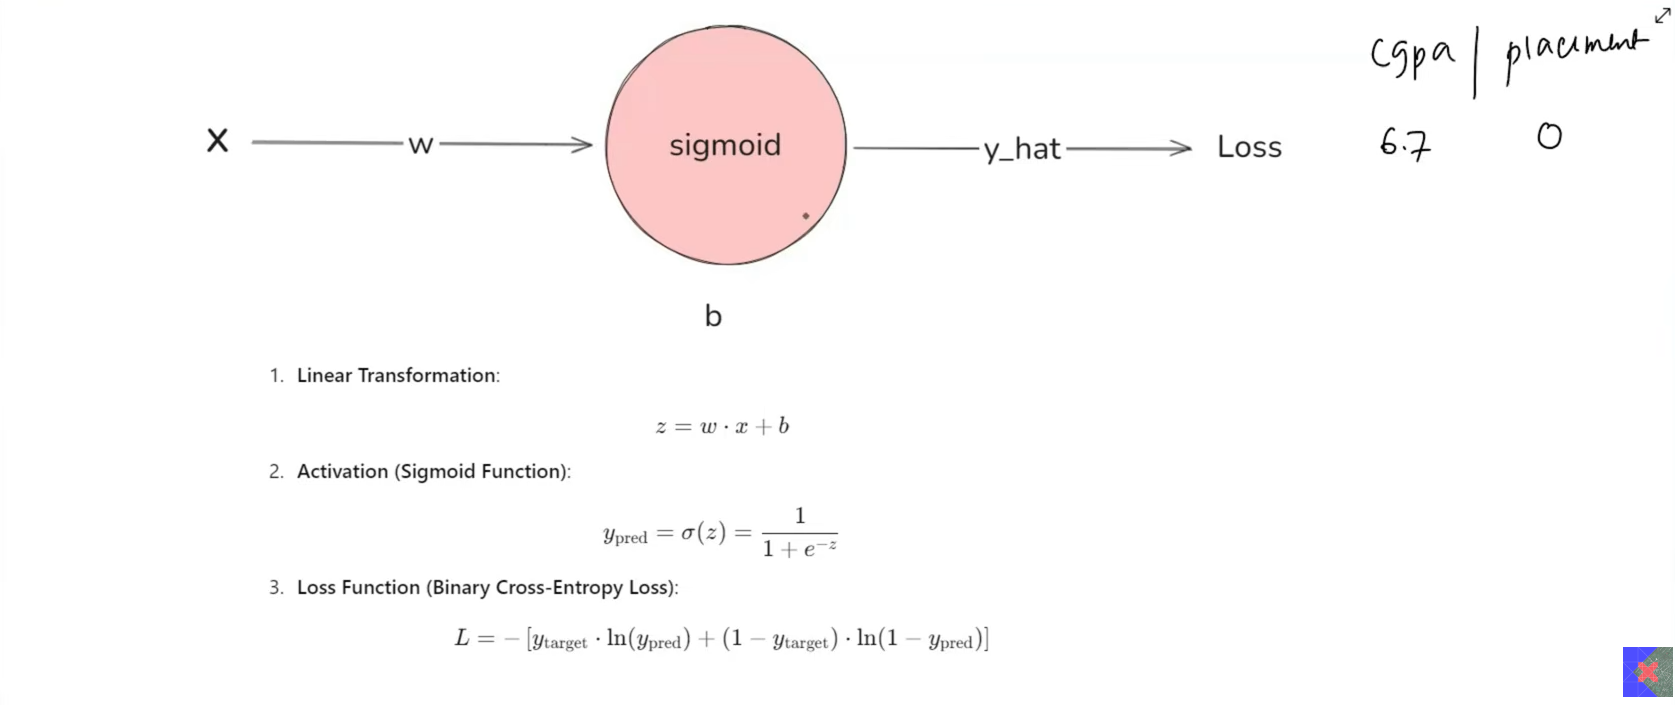**

In [ ]:
# Inputs
x = torch.tensor(6.7)  # Input feature
y = torch.tensor(0.0)  # True label (binary)


# Initial Weights/Parameters
w = torch.tensor(1.0)  # Weight
b = torch.tensor(0.0)  # Bias

**torch.clamp()**
in PyTorch is used to restrict tensor values within a specified minimum and maximum range.

Any value below the minimum is replaced by the minimum, and any value above the maximum is replaced by the maximum.

In [ ]:
# Binary Cross-Entropy Loss for scalar
def binary_cross_entropy_loss(prediction, target):
    epsilon = 1e-8  # To prevent log(0)
    prediction = torch.clamp(prediction, epsilon, 1 - epsilon)
    return -(target * torch.log(prediction) + (1 - target) * torch.log(1 - prediction))

In [ ]:
# Forward pass
z = w * x + b  # Weighted sum (linear part)
y_pred = torch.sigmoid(z)  # Predicted probability

# Compute binary cross-entropy loss
loss = binary_cross_entropy_loss(y_pred, y)

In [ ]:
loss

tensor(6.7012)

**Backpropagation**

In [ ]:
# Derivatives:
# 1. dL/d(y_pred): Loss with respect to the prediction (y_pred)
dloss_dy_pred = (y_pred - y)/(y_pred*(1-y_pred))

# 2. dy_pred/dz: Prediction (y_pred) with respect to z (sigmoid derivative)
dy_pred_dz = y_pred * (1 - y_pred)

# 3. dz/dw and dz/db: z with respect to w and b
dz_dw = x  # dz/dw = x
dz_db = 1  # dz/db = 1 (bias contributes directly to z)

dL_dw = dloss_dy_pred * dy_pred_dz * dz_dw
dL_db = dloss_dy_pred * dy_pred_dz * dz_db

In [ ]:
print(f"Manual Gradient of loss w.r.t weight (dw): {dL_dw}")
print(f"Manual Gradient of loss w.r.t bias (db): {dL_db}")

Manual Gradient of loss w.r.t weight (dw): 6.691762447357178
Manual Gradient of loss w.r.t bias (db): 0.998770534992218


# **Now With AutoGrad**

In [ ]:
x = torch.tensor(6.7)
y = torch.tensor(0)

In [ ]:
w = torch.tensor(1.0, requires_grad=True) # Set requires_grad=True for the variable with respect to which we want to calculate the gradient.
b = torch.tensor(0.0, requires_grad=True) # Set requires_grad=True for the variable with respect to which we want to calculate the gradient.

In [ ]:
w

tensor(1., requires_grad=True)

In [ ]:
b

tensor(0., requires_grad=True)

In [ ]:
# Linear Transformation
z = w*x + b
z

tensor(6.7000, grad_fn=<AddBackward0>)

In [ ]:
# Sigmoid Function
y_pred = torch.sigmoid(z)
y_pred

tensor(0.9988, grad_fn=<SigmoidBackward0>)

In [ ]:
# loss
loss = binary_cross_entropy_loss(y_pred, y)
loss

tensor(6.7012, grad_fn=<NegBackward0>)

In [ ]:
loss.backward()

In [ ]:
print(w.grad)
print(b.grad)

tensor(6.6918)
tensor(0.9988)


# **AutoGrad with Vector Input Tensors**

In [ ]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

In [ ]:
x

tensor([1., 2., 3.], requires_grad=True)

In [ ]:
y = (x**2).mean()
y

tensor(4.6667, grad_fn=<MeanBackward0>)

In [ ]:
y.backward()

In [ ]:
x.grad

tensor([0.6667, 1.3333, 2.0000])

**Clearing Grad**

In PyTorch, clearing gradients means resetting the previously accumulated gradients to zero before calculating gradients for the next training step.

We usually do this using optimizer.zero_grad().
1. Why do we need to clear gradients?
  
   By default, PyTorch accumulates gradients instead of overwriting them.

In [ ]:
# clearing grad
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [ ]:
# Forward pass
y = x ** 2
y

tensor(4., grad_fn=<PowBackward0>)

In [ ]:
# Backward pass
y.backward()

In [ ]:
x.grad

tensor(4.)

In [ ]:
y = x ** 2
y.backward()

print(x.grad)

tensor(8.)


Why is the second result 8 instead of 4?

Because PyTorch adds the new gradient to the existing gradient:
\[
4 + 4 = 8
\]

If you intended to calculate the gradient independently each time, you need to clear the old gradient first.



**How to clear gradients**

For a standalone tensor, you can use:

In [ ]:
# Clear the previous gradient

x.grad.zero_()


tensor(0.)

For Neural Network  **optimizer.zero_grad()**

**disabling gradient tracking**

In PyTorch, disabling gradient tracking means telling Autograd not to record operations for gradient calculation. It is useful when we only want predictions and do not need to train or update the model.

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [ ]:
y = x ** 2
y

tensor(4., grad_fn=<PowBackward0>)

In [ ]:
y.backward()

In [ ]:
x.grad

tensor(4.)

option 1 - **requires_grad_(False)**

option 2 - **detach()**

option 3 - **torch.no_grad()**

In [ ]:
# Option 1 - requires_grad_(False)
x.requires_grad_(False)

tensor(2.)

In [ ]:
x

tensor(2.)

In [ ]:
y = x ** 2

In [ ]:
y

tensor(4.)

In [ ]:
y.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
# Option 2 - detach()
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [ ]:
z = x.detach()
z

tensor(2.)

In [ ]:
y = x ** 2
y

tensor(4., grad_fn=<PowBackward0>)

In [ ]:
y1 = z ** 2
y1

tensor(4.)

In [ ]:
y.backward()

In [ ]:
y1.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
#Option 3 - torch.no_grad()
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [ ]:
with torch.no_grad():
  y = x ** 2

In [ ]:
y

tensor(4.)

In [ ]:
y.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn